### Business report
1. Best-Seller Performance

Grocery (5.81%), Smart Home Security & Lighting (5.77%), and Health & Personal Care (5.77%) have the highest best-seller proportions. Category differences are evident, although the Chi-Square test requires caution due to low expected frequencies.

2. Product Pricing

Motherboards have the highest average price (£68.77), while Desktop PCs lead in median price (£74). Pricing varies substantially across categories.

3. Customer Ratings

Handmade categories dominate customer satisfaction rankings, with three categories achieving median ratings of 5.0 stars among rated products.

4. Price vs. Customer Ratings

Virtually no linear correlation exists between product price and ratings (r = 0.007). Higher prices do not consistently translate into better customer ratings. Other numerical correlations are also weak.

##### Business Conclusion

Product category matters more than price alone when evaluating product positioning. Businesses should prioritize category-specific pricing, customer satisfaction, and competitive positioning rather than assuming premium prices guarantee better ratings or performance.

###### Analysis excludes price outliers and treats zero-star ratings as unrated products.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("C:/Users/yurii/Downloads/IH_Labs/week5/amz_uk_price_prediction_dataset.csv")

In [5]:
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1

In [9]:
df[["category", "isBestSeller"]].head(10)

,category,isBestSeller
0,Hi-Fi Speakers,False
1,Hi-Fi Speakers,True
2,Hi-Fi Speakers,False
3,Hi-Fi Speakers,False
4,Hi-Fi Speakers,False
5,Hi-Fi Speakers,False
6,Hi-Fi Speakers,False
7,Hi-Fi Speakers,False
8,Hi-Fi Speakers,False
9,Hi-Fi Speakers,False


In [14]:
best_sellers_share = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")
best_sellers_share

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [16]:
best_sellers_share[True].sort_values(ascending=False)*100

category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
                                    ...   
Bedding Collections               0.000000
CPUs                              0.000000
CD, Disc & Tape Players           0.000000
Blank Media Cases & Wallets       0.000000
eBook Readers & Accessories       0.000000
Name: True, Length: 296, dtype: float64

##### Grocery, Smart Home Security & Lighting, and Health & Personal Care have the highest proportions of best-sellers (around 5.8%). Best-seller prevalence varies across product categories, suggesting category-specific differences in product performance.

In [17]:
from scipy.stats import chi2_contingency

In [19]:
contingency_table = pd.crosstab(df["category"], df["isBestSeller"])
contingency_table

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [21]:
chi2, p_value, dof, expected = chi2_contingency(contingency_table)
p_value


np.float64(0.0)

In [23]:
# Select top 15 categories by product count
top_15 = df["category"].value_counts().head(15).index
top_15

Index(['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories',
       'Bath & Body', 'Birthday Gifts', 'Manicure & Pedicure Products',
       'Skin Care', 'Make-up', 'Hair Care', 'Fragrances', 'Handmade Gifts',
       'Handmade Home Décor', 'Luggage and travel gear', 'Handmade Jewellery',
       'Handmade Artwork'],
      dtype='str', name='category')

In [25]:
# Create a normalized crosstab
crosstab_top15 = pd.crosstab(
    df.loc[df["category"].isin(top_15), "category"],
    df.loc[df["category"].isin(top_15), "isBestSeller"],
    normalize="index"
) * 100

crosstab_top15

isBestSeller,False,True
category,,
Bath & Body,99.827153,0.172847
Beauty,98.436205,1.563795
Birthday Gifts,99.815576,0.184424
Fragrances,99.924585,0.075415
Hair Care,99.626368,0.373632
Handmade Artwork,99.977626,0.022374
"Handmade Clothing, Shoes & Accessories",99.927193,0.072807
Handmade Gifts,99.759497,0.240503
Handmade Home Décor,99.873250,0.126750


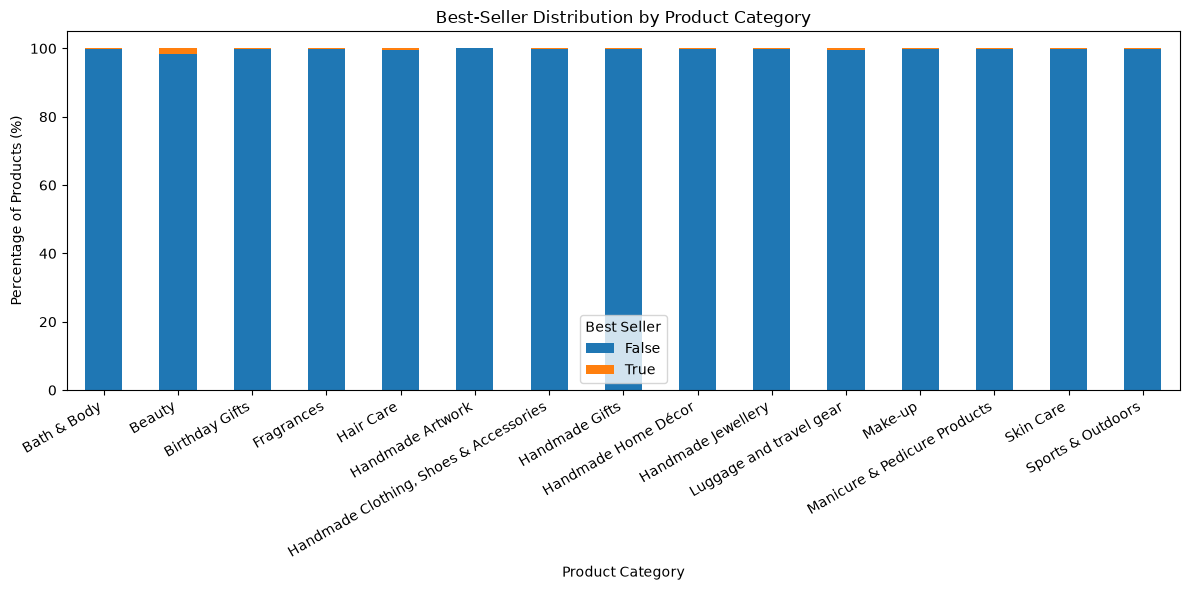

In [32]:
crosstab_top15.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.title("Best-Seller Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Percentage of Products (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Best Seller")
plt.tight_layout()
plt.show()

##### Best-seller products represent a very small share of the top 15 largest product categories. The distribution is heavily dominated by non-best-sellers, with relatively minor differences between categories.

### Part 2

In [35]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1

iqr

np.float64(36.0)

In [36]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [ ]:
df_clean = df[(df["price"] >= lower) & (df["price"] <= upper)]

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers


In [42]:
print(len(df))
print(len(df_clean))

2443651
2115963


In [44]:
top_20 = df_clean["category"].value_counts().head(20).index
top_20

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='str', name='category')

In [ ]:
df_top20 = df_clean[df_clean["category"].isin(top_20)]
df_top20

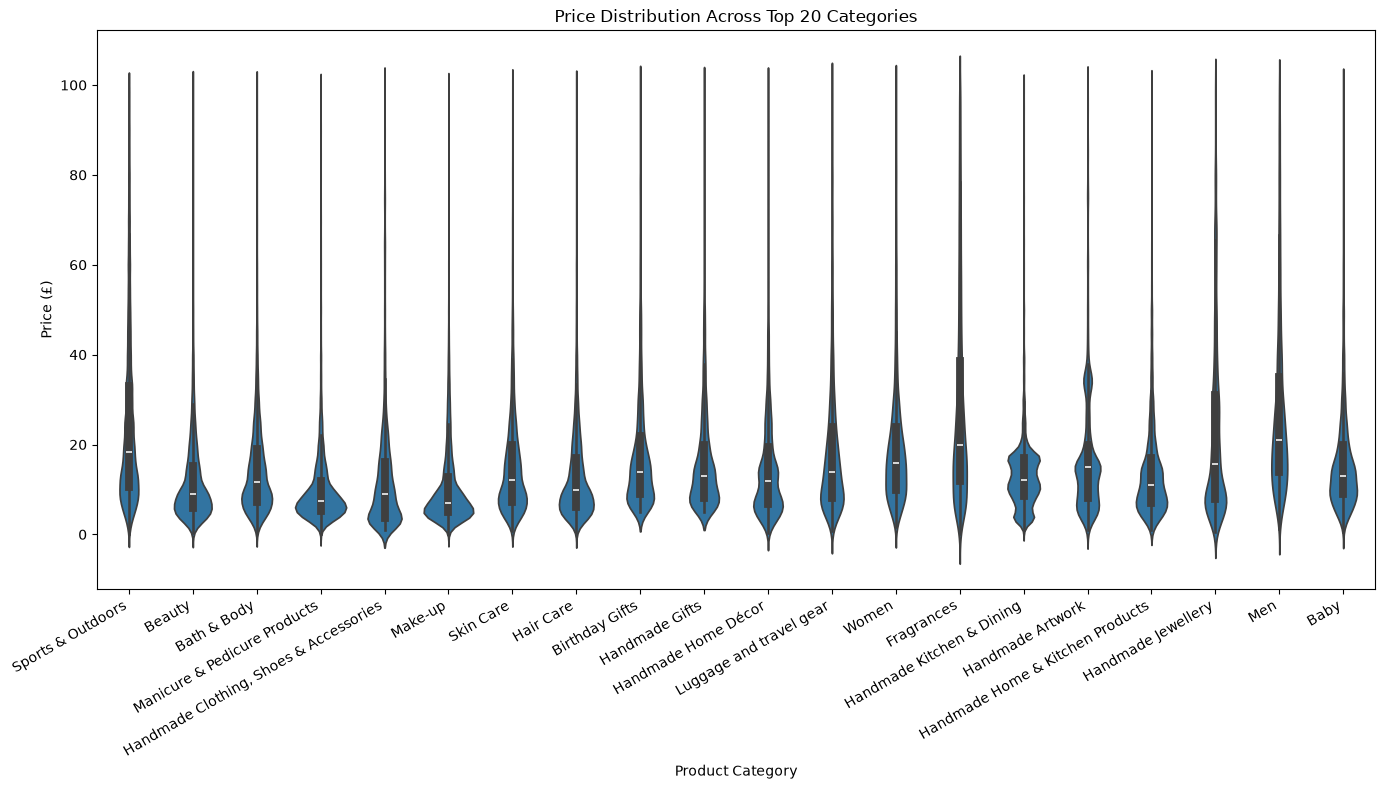

In [50]:
plt.figure(figsize=(14, 8))

sns.violinplot(
    data=df_top20,
    x="category",
    y="price",
    order=top_20
)

plt.title("Price Distribution Across Top 20 Categories")
plt.xlabel("Product Category")
plt.ylabel("Price (£)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##### Most products across the top 20 categories are concentrated in the lower price ranges, generally below £20.

In [51]:
median_prices = df_clean.groupby("category")["price"].median()

In [52]:
median_prices.sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

##### Desktop PCs have the highest median price (£74), followed by Boxing Shoes (£69.79) and Tablets (£69), after removing price outliers.

In [53]:
top_10 = df_clean["category"].value_counts().head(10).index

avg_prices = df_clean[df_clean["category"].isin(top_10)].groupby("category")["price"].mean()

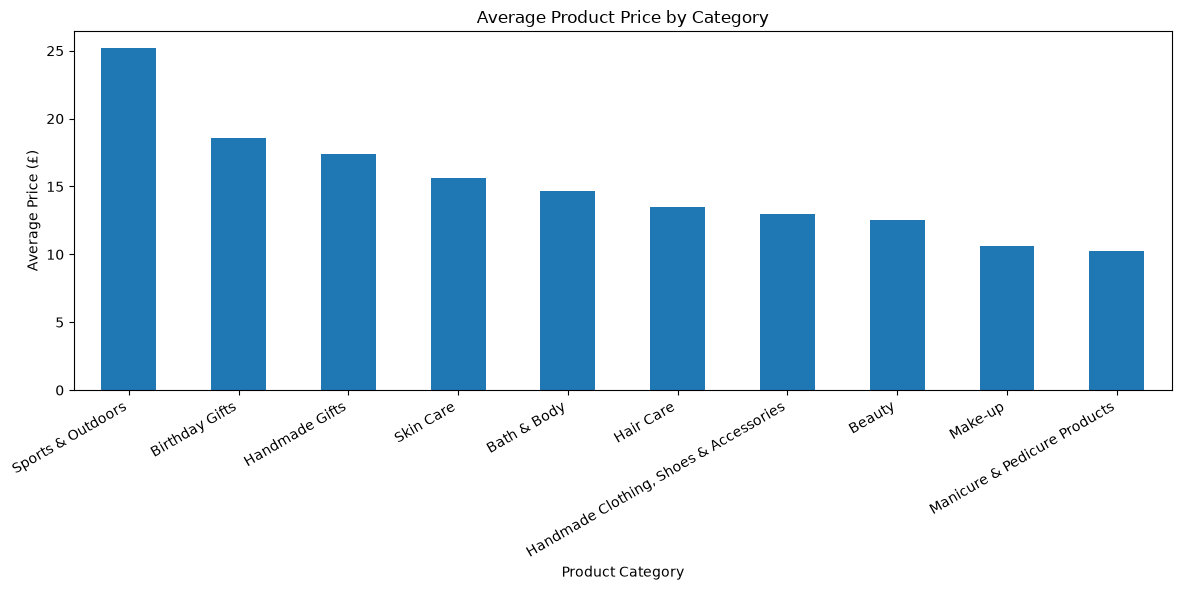

In [55]:
plt.figure(figsize=(12, 6))

avg_prices.sort_values(ascending=False).plot(kind="bar")

plt.title("Average Product Price by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##### Sports & Outdoors has the highest average price (£25) among the 10 largest product categories, while Manicure & Pedicure Products has the lowest (£10). This suggests substantial pricing differences across product categories.

In [56]:
average_prices = df_clean.groupby("category")["price"].mean()

average_prices.sort_values(ascending=False).head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

##### Motherboards have the highest average price (£68.77), followed by Boxing Shoes (£67.42) and Desktop PCs (£66.92), after removing price outliers.

In [58]:
top_10 = df_clean["category"].value_counts().head(10).index
top_10

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='str', name='category')

In [59]:
df_top10 = df_clean[df_clean["category"].isin(top_10)]

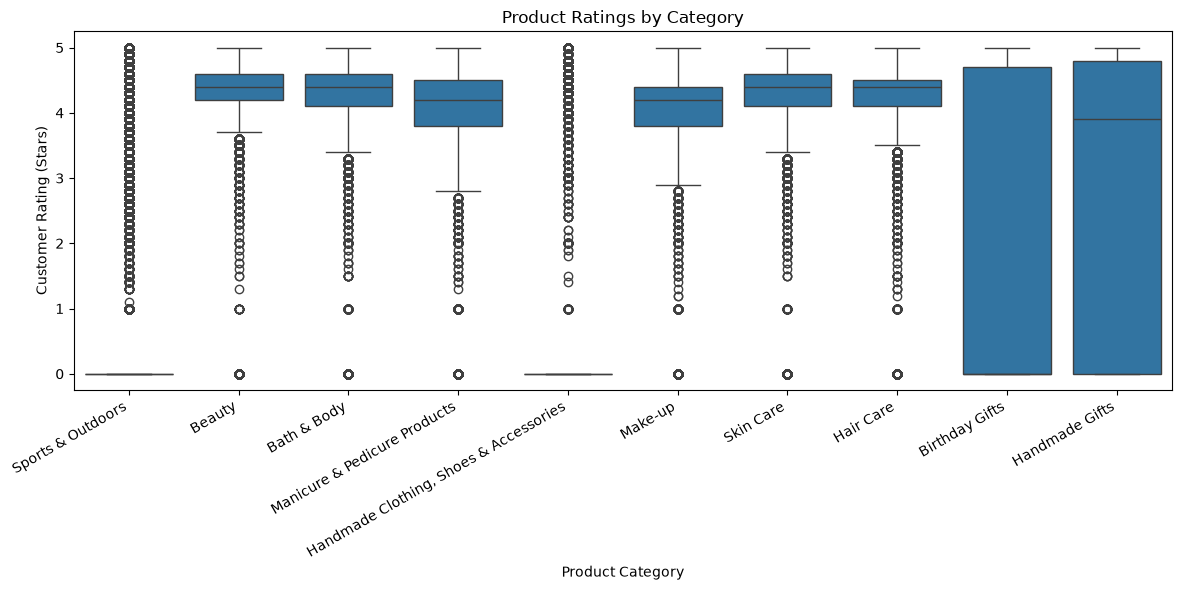

In [61]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_top10,
    x="category",
    y="stars",
    order=top_10
)

plt.title("Product Ratings by Category")
plt.xlabel("Product Category")
plt.ylabel("Customer Rating (Stars)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [62]:
df_rated = df_clean[df_clean["stars"] > 0]

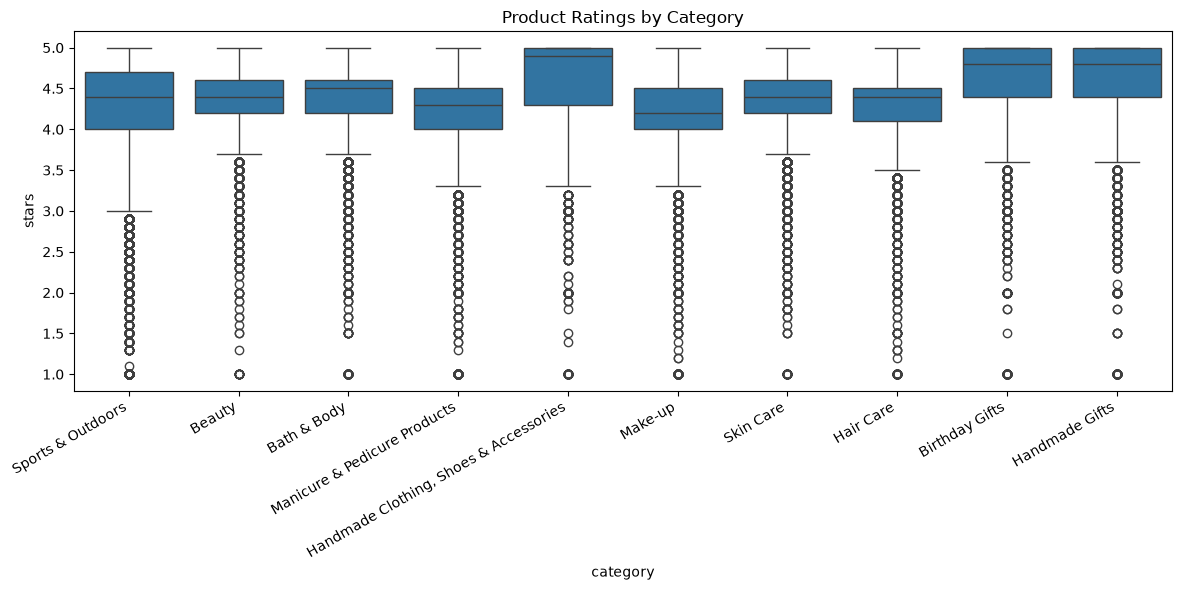

In [64]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_rated[df_rated["category"].isin(top_10)],
    x="category",
    y="stars",
    order=top_10
)

plt.title("Product Ratings by Category")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##### Most categories have high median ratings (4.2–4.9 stars), indicating generally positive customer feedback. Handmade Clothing, Birthday Gifts and Handmade Gifts stand out with the highest ratings, suggesting stronger customer satisfaction among rated products.

In [65]:
median_ratings = df_rated.groupby("category")["stars"].median()

median_ratings.sort_values(ascending=False).head(10)

category
Handmade Artwork                          5.0
Made in Italy Handmade                    5.0
Handmade Baby Products                    5.0
Handmade Clothing, Shoes & Accessories    4.9
Handmade Kitchen & Dining                 4.9
Birthday Gifts                            4.8
Handmade Home Décor                       4.8
Handmade Gifts                            4.8
Handmade Home & Kitchen Products          4.7
Computer Memory                           4.7
Name: stars, dtype: float64

##### Handmade Artwork, Made in Italy Handmade, and Handmade Baby Products have the highest median ratings (5.0 stars). Handmade categories dominate the top rankings, suggesting strong customer satisfaction among rated products.

### Part 3

In [67]:
df_rated[["price", "stars"]]

,price,stars
0,21.99,4.7
1,23.99,4.7
2,21.99,4.7
3,31.99,4.7
4,17.99,4.6
...,...,...
2443639,49.99,3.6
2443642,49.99,3.6
2443644,14.99,3.6
2443649,79.99,4.3


In [66]:
correlation = df_rated["price"].corr(df_rated["stars"])

correlation

np.float64(0.00674450806715802)

##### Product price and customer ratings show virtually no linear correlation. Higher-priced products do not consistently receive higher or lower ratings.

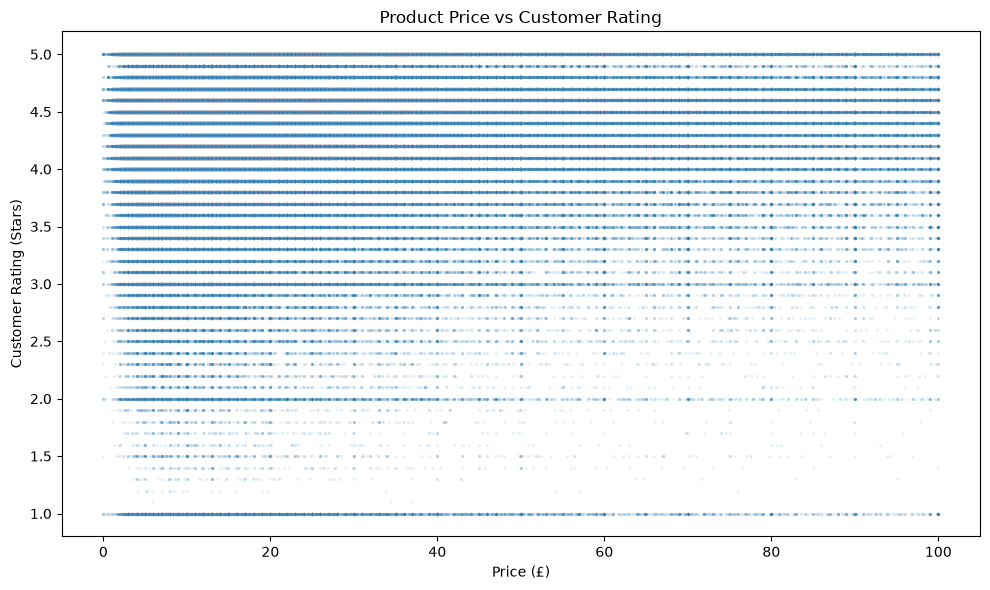

In [71]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_rated,
    x="price",
    y="stars",
    alpha=0.1,
    s=5
)

plt.title("Product Price vs Customer Rating")
plt.xlabel("Price (£)")
plt.ylabel("Customer Rating (Stars)")
plt.tight_layout()
plt.show()

In [72]:
numeric_df = df_rated.select_dtypes(include="number")

In [74]:
correlation_matrix = numeric_df.corr()
correlation_matrix

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,-0.007732,0.023756,-0.031275,0.018386
stars,-0.007732,1.000000,0.033487,0.006745,0.039851
reviews,0.023756,0.033487,1.000000,-0.003168,0.097969
price,-0.031275,0.006745,-0.003168,1.000000,-0.073517
boughtInLastMonth,0.018386,0.039851,0.097969,-0.073517,1.000000


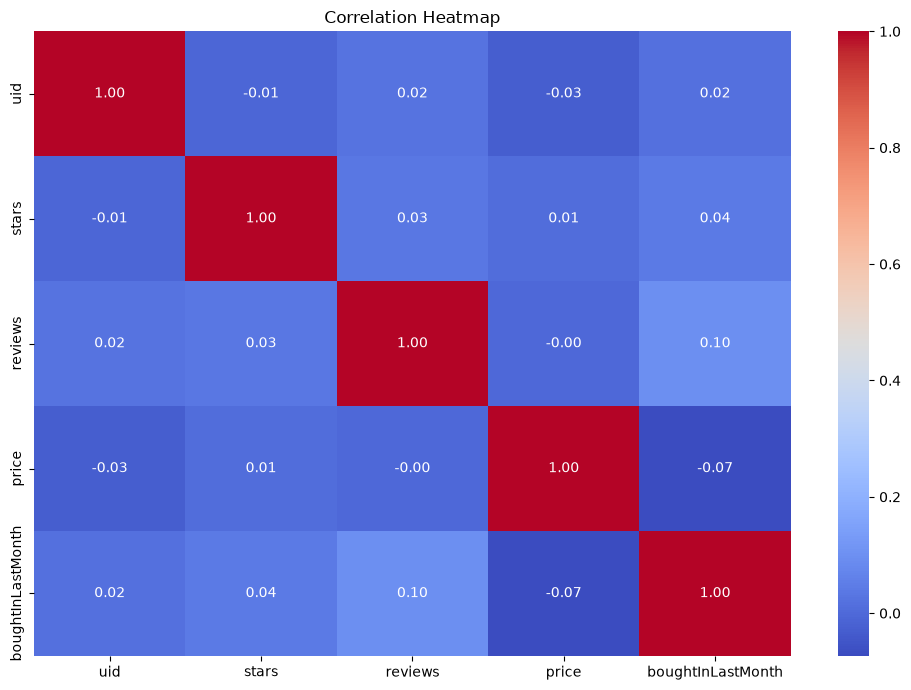

In [75]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

##### All numerical variables show very weak linear correlations. Price has virtually no relationship with customer ratings (r ≈ 0.01) or review counts (r ≈ 0.00). Monthly purchases show a weak positive correlation with reviews (r = 0.10). Overall, price and ratings alone provide little insight into product demand.